# Baseline results

The first sections retain the historical Haiku comparison. The final section loads the four new one-word judges (Qwen2.5-7B, Qwen3-30B, Llama-3.1-8B, and GPT-5.5) from `results/new_submissions/baselines/`, with a protocol audit and documented full-answer correctness reviews for previously ungraded decisions. See [run commands](../docs/BASELINE_MODEL_RUNS.md).

Completed corrected baselines from `results/onepool_parsing_fixed/`, compared with VeriFin on the same frozen candidate pools. The cells load saved results, call the **original scoring policy**, and calculate the tables and comparison plot directly. No model calls. Set `RUN_ROOT` in the loading cell to the completed rerun directory (for example, `results/llm_judge_20261016`).

The original scorer compares the magnitudes of stored numeric claims with the gold's numeric targets using **max(1, 1% × |target|)** tolerance and the original manual adjudications. The same rule applies to every method. All questions and saved decisions remain in the comparison; no reference-based exclusions or strict-rounding rescoring are applied.

The comparison includes **LLM Judge** and **VeriFin**. LLM Judge checks the generated answer against filing evidence without receiving the gold answer. These logs do not establish generator/planner backbone parity.

The saved LLM Judge used question-specific comparison tolerances (±0.5 million for XBRLFiling), while the restored evaluation metric uses the original 1% rule. Restoring the scorer changes grading only; it does not regenerate their decisions.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import importlib
import json
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src/verifiqa").is_dir() and (path / "data/scoring").is_dir())
for path in (ROOT, ROOT / "src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
# Rerunning this cell refreshes the scorer in an existing notebook kernel.
importlib.invalidate_caches()
for name in ("verifiqa.eval.candidate_scoring", "verifiqa.eval.baseline_scoring",
             "scripts.paper_scoring", "scripts.build_publication_artifacts",
             "scripts.baseline_annotations", "scripts.baseline_reference_screening",
             "scripts.baseline_full_answer_review", "scripts.reviewer_baselines"):
    importlib.reload(importlib.import_module(name))

import pandas as pd
from IPython.display import Markdown, display
from scripts import paper_scoring, reviewer_baselines


def readable_table(table, caption, formats=None):
    return (table.style.format(formats or {}, na_rep="—").set_caption(caption)
            .set_table_styles([
                {"selector": "caption", "props": [("text-align", "left"), ("font-weight", "bold"), ("padding", "8px 0")]},
                {"selector": "th", "props": [("text-align", "left")]},
                {"selector": "td", "props": [("padding", "6px 8px"), ("white-space", "nowrap")]},
            ]))

## Load and validate the saved runs

Use the [original policy](../data/scoring/scoring_policy.json) and its [original adjudications](../data/scoring/manual_adjudications.json). Execution manifests, dataset IDs, and shared generated candidates are validated before scoring. The candidate protocol remains attached to every saved row; the original metric is explicitly enabled for the corrected baseline inputs.

The later strict reference/candidate annotations do not enter this calculation. Legacy `UNVERIFIED_FORMULA` verdicts are counted under `ABSTAIN`, with their original status retained in the per-question export.

In [2]:
# Change this after completing a fresh judge-only run, e.g. "results/llm_judge_20261016".
RUN_ROOT = "results/onepool_parsing_fixed"
SCORING_VIEW = "original"
SELECTED_METHODS = ("LLM Judge", "VeriFin")
COMPARISON_BASELINES = ("LLM Judge",)
inputs = reviewer_baselines.load_inputs(ROOT, run_root=RUN_ROOT, scoring_view=SCORING_VIEW,
                                        methods=("judge",))
policy = inputs["policy"]
adjudications = inputs["adjudications"]
loaded_runs = inputs["loaded_runs"]
source_hashes = inputs["source_hashes"]
SCORING_PROTOCOL = policy["candidate_correctness"]["protocol"]
assert SCORING_PROTOCOL == "legacy_magnitude_any_token_v1"
assert policy["candidate_correctness"]["allow_corrected_candidate_protocol"] is True
assert len(loaded_runs) == 4
assert not inputs["normalization_provenance"]["references"]
assert not inputs["normalization_provenance"]["candidates"]

display(Markdown(f"**Run directory:** `{RUN_ROOT}`. **Scoring:** original magnitude/any-gold-number rule, "
                 f"with max(1, 1% of target) tolerance. **Original adjudications:** {len(adjudications)}. "
                 f"**Displayed runs:** {len(loaded_runs)}."))

**Run directory:** `results/onepool_parsing_fixed`. **Scoring:** original magnitude/any-gold-number rule, with max(1, 1% of target) tolerance. **Original adjudications:** 6. **Displayed runs:** 4.

## Score every saved result

Each method uses the same `paper_scoring.score_rows` call and policy. Corrected baselines retain their validated candidate identity and execution metadata. This restores the evaluation rule; it does not regenerate answers or change verifier decisions.

In [3]:
def score_saved_runs(bundle):
    scored_records = []
    for run in bundle["loaded_runs"]:
        for source_row, record in enumerate(run["records"], 1):
            # Original scorer; the same policy and adjudications for every method.
            counts = paper_scoring.score_rows([record], run["dataset"], bundle["policy"], bundle["adjudications"])
            outcome, = [name for name, count in counts.items() if count]
            scored_records.append(dict(
                dataset=run["dataset"], method=run["method"], id=paper_scoring.record_id(record),
                status=record["status"], source_status=record.get("source_status", record["status"]),
                source_path=run["result_path"], source_sha256=bundle["source_hashes"][run["result_path"]],
                source_row=source_row, outcome=outcome,
            ))
    return pd.DataFrame(scored_records)


question_outcomes = score_saved_runs(inputs)

## Calculate the comparison

TA/FA are correct/incorrect accepted claims under the original scoring policy; TR/FR are incorrect/correct rejected claims. **Precision** = TA / (TA + FA); **decision accuracy** = (TA + TR) / (TA + FA + TR + FR). **Coverage** = (saved VERIFIED + saved VIOLATED) / N; **abstention** = saved ABSTAIN / N.

Every question remains in N. The original scorer uses the stored numeric claim, so its treatment of narrative answers differs from the later strict scorer. Undefined rates remain missing, not zero.

In [4]:
def tabulate_outcomes(bundle, question_outcomes):
    table_rows = []
    for run in bundle["loaded_runs"]:
        selected = question_outcomes[(question_outcomes["dataset"] == run["dataset"])
                                    & (question_outcomes["method"] == run["method"])]
        statuses, counts = Counter(selected["status"]), Counter(selected["outcome"])
        total = len(selected)
        accepted, rejected = statuses["VERIFIED"], statuses["VIOLATED"]
        scored_accepts = counts["TA"] + counts["FA"]
        scored_decisions = scored_accepts + counts["TR"] + counts["FR"]
        assert sum(counts.values()) == total
        table_rows.append({
            "Dataset": run["dataset_label"], "Method": run["method"], "N": total,
            **{name: statuses[name] for name in ("VERIFIED", "VIOLATED", "ABSTAIN")},
            **{name: counts[name] for name in ("TA", "FA", "TR", "FR")}, "Unscored": 0,
            "Reference excluded": 0, "Eligible N": total,
            "Scored accepts": scored_accepts, "Scored decisions": scored_decisions,
            "Precision (%)": 100 * counts["TA"] / scored_accepts if scored_accepts else None,
            "Decision accuracy (%)": 100 * (counts["TA"] + counts["TR"]) / scored_decisions if scored_decisions else None,
            "Coverage (%)": 100 * (accepted + rejected) / total,
            "Abstention (%)": 100 * statuses["ABSTAIN"] / total,
        })
    results = pd.DataFrame(table_rows).set_index(["Dataset", "Method"])
    assert (results[["VERIFIED", "VIOLATED", "ABSTAIN"]].sum(axis=1) == results["N"]).all()
    return results


results = tabulate_outcomes(inputs, question_outcomes)

In [5]:
count_columns = ["N", "VERIFIED", "VIOLATED", "ABSTAIN", "TA", "FA", "TR", "FR"]
rate_columns = ["Precision (%)", "Decision accuracy (%)", "Coverage (%)", "Abstention (%)"]
comparison_table = results[count_columns + rate_columns]
display(readable_table(comparison_table,
                       "Full saved runs · original scoring policy",
                       {**{name: "{:.0f}" for name in count_columns},
                        **{name: "{:.2f}" for name in rate_columns}}))

## Baseline comparison plot

The archived grouped-bar layout now reads directly from `comparison_table` above: precision among scored accepts, accuracy among scored decisions, and abstention over all N questions. Labels above each method are **false-accept counts**. The same original scoring policy applies to the table and plot; the Wilson intervals and significance tests follow below.

Exports: [PDF](../figures/baseline_comparison_original_scoring.pdf) · [PNG](../figures/baseline_comparison_original_scoring.png).

Saved: figures/baseline_comparison_original_scoring (.pdf and .png)


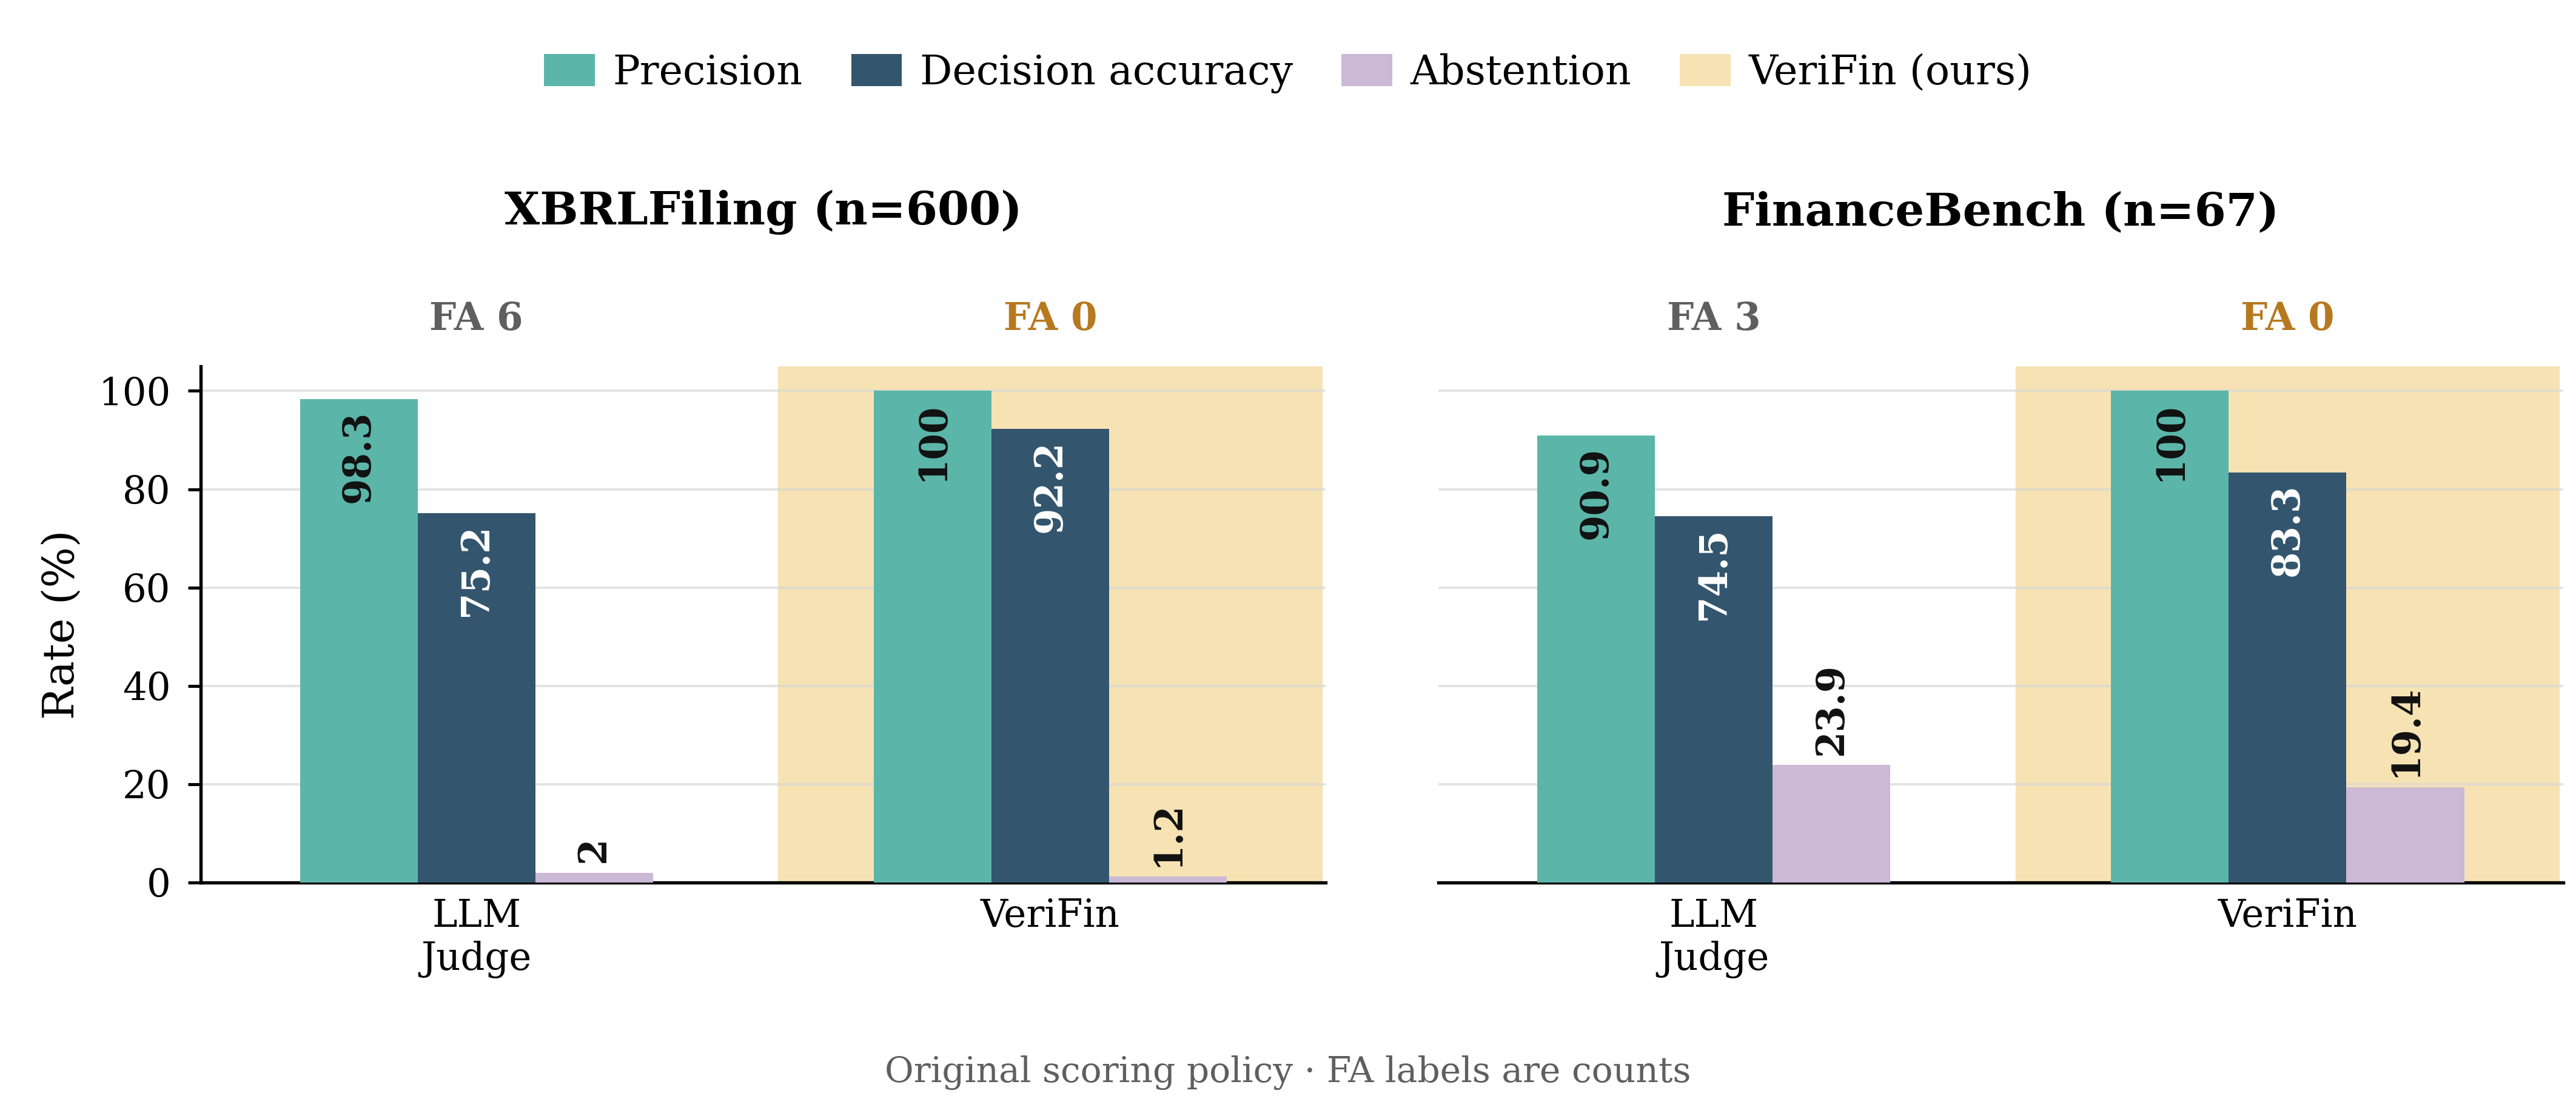

In [6]:
"""Baseline comparison using the corrected runs and this notebook's scorer.

Layout adapted from the archived agent_financebench_result_metrics notebook.
All values come from comparison_table; no historical result values are used.
"""
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from matplotlib.patches import Patch


METHOD_LABELS = ["LLM\nJudge", "VeriFin"]
RESULT_METHODS = list(SELECTED_METHODS)
METRICS = ("Prec", "Acc", "Abst")
METRIC_COLUMNS = {
    "Prec": "Precision (%)", "Acc": "Decision accuracy (%)", "Abst": "Abstention (%)"
}
COLORS = {"Prec": "#5bb6a9", "Acc": "#33566e", "Abst": "#cbb9d6"}
METRIC_LABELS = {
    "Prec": "Precision", "Acc": "Decision accuracy", "Abst": "Abstention"
}
HIGHLIGHT = "#f6e2b3"
HIGHLIGHT_EDGE = "#b7791f"


def _panel(dataset):
    rows = comparison_table.xs(dataset, level="Dataset").loc[RESULT_METHODS]
    if rows["N"].nunique() != 1:
        raise ValueError(f"{dataset}: methods have different dataset sizes")
    data = {key: rows[column].to_numpy(dtype=float)
            for key, column in METRIC_COLUMNS.items()}
    for values in data.values():
        finite = values[np.isfinite(values)]
        if ((finite < 0) | (finite > 100)).any():
            raise ValueError(f"{dataset}: rates must be percentages in [0, 100]")
    data["FA"] = rows["FA"].to_numpy(dtype=int)
    data["N"] = int(rows["N"].iloc[0])
    return data


def _add_value(ax, x_pos, value, metric):
    if not np.isfinite(value):
        ax.annotate("N/A", (x_pos, 0), xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", rotation=90, fontsize=7, color="#777777")
        return
    label = f"{value:.1f}".removesuffix(".0")
    if value == 0:
        ax.annotate(
            label, (x_pos, 0), xytext=(0, 2.0), textcoords="offset points",
            ha="center", va="bottom", rotation=90, fontsize=7.0,
            fontweight="semibold", color="#8a8a8a", clip_on=True, zorder=5,
        )
        return

    # Tall bars carry their labels inside the bar; short bars place them above.
    if value >= 24:
        color = "white" if metric == "Acc" else "#111111"
        ax.annotate(
            label, (x_pos, value), xytext=(0, -2.2), textcoords="offset points",
            ha="center", va="top", rotation=90, fontsize=7.5,
            fontweight="bold", color=color, clip_on=True, zorder=5,
        )
    else:
        ax.annotate(
            label, (x_pos, value), xytext=(0, 2.0), textcoords="offset points",
            ha="center", va="bottom", rotation=90, fontsize=7.5,
            fontweight="bold", color="#111111", clip_on=True, zorder=5,
        )


def _plot_panel(ax, data, title, show_y):
    centers = np.arange(len(METHOD_LABELS), dtype=float)
    bar_width = 0.205

    verifin_index = RESULT_METHODS.index("VeriFin")
    ax.axvspan(verifin_index - 0.47, verifin_index + 0.47, color=HIGHLIGHT, zorder=0)
    for metric_index, metric in enumerate(METRICS):
        positions = centers + (metric_index - 1) * bar_width
        bars = ax.bar(
            positions,
            data[metric],
            width=bar_width,
            color=COLORS[metric],
            edgecolor="none",
            linewidth=0,
            zorder=3,
        )
        for position, value in zip(positions, data[metric]):
            _add_value(ax, position, value, metric)

    # FA is a count, not a percentage: place it in a dedicated row above the axis.
    for index, (center, count) in enumerate(zip(centers, data["FA"])):
        ax.text(
            center,
            1.055,
            f"FA {count}",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=7.5,
            fontweight="bold",
            color=HIGHLIGHT_EDGE if index == len(centers) - 1 else "#5f5f5f",
            clip_on=False,
        )

    ax.text(
        0.5, 1.255, title, transform=ax.transAxes, ha="center", va="bottom",
        fontsize=9.0, fontweight="bold", clip_on=False,
    )
    ax.set_xlim(-0.48, len(METHOD_LABELS) - 0.52)
    ax.set_ylim(0, 105)
    ax.set_yticks(np.arange(0, 101, 20))
    ax.set_xticks(centers)
    ax.set_xticklabels(METHOD_LABELS, fontsize=7.5)
    ax.tick_params(axis="x", length=0, pad=3)
    ax.tick_params(axis="y", labelsize=7.5, width=0.6, length=2.5)
    if show_y:
        ax.set_ylabel("Rate (%)", fontsize=8.5, labelpad=3)
    else:
        ax.tick_params(axis="y", labelleft=False, left=False)
        ax.spines["left"].set_visible(False)

    ax.grid(axis="y", color="#d7d7d7", linewidth=0.45, alpha=0.72, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_linewidth(0.65)
    if show_y:
        ax.spines["left"].set_linewidth(0.65)


output_stem = ROOT / "figures" / "baseline_comparison_original_scoring"
output_stem.parent.mkdir(parents=True, exist_ok=True)

with plt.rc_context({
    "font.family": "serif",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    fig, axes = plt.subplots(1, 2, figsize=(7.08, 3.05), sharey=True)
    for index, dataset in enumerate(("XBRLFiling", "FinanceBench")):
        data = _panel(dataset)
        _plot_panel(axes[index], data, f"{dataset} (n={data['N']})", index == 0)

    legend = [
        Patch(
            facecolor=COLORS[metric], edgecolor="none", linewidth=0,
            label=METRIC_LABELS[metric],
        )
        for metric in METRICS
    ]
    legend.append(
        Patch(
            facecolor=HIGHLIGHT, edgecolor="none", linewidth=0,
            label="VeriFin (ours)",
        )
    )
    fig.legend(
        handles=legend, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.985),
        frameon=False, fontsize=8.0, handlelength=1.25, handleheight=0.85,
        handletextpad=0.45, columnspacing=1.2,
    )
    fig.subplots_adjust(
        left=0.078, right=0.995, bottom=0.205, top=0.67, wspace=0.10
    )
    fig.text(0.5, 0.025, "Original scoring policy · FA labels are counts",
             ha="center", fontsize=7, color="#5f5f5f")
    fig.savefig(output_stem.with_suffix(".pdf"), facecolor="white")
    fig.savefig(output_stem.with_suffix(".png"), dpi=600, facecolor="white")
    print("Saved:", output_stem.relative_to(ROOT), "(.pdf and .png)")
    # Embed the exported PNG so saved notebook previews also show the plot.
    display(Image(filename=str(output_stem.with_suffix(".png")), width=1000))
    plt.close(fig)


## Precision uncertainty: 95% Wilson intervals

Compute pointwise **95% Wilson confidence intervals** from the scorer's TA successes out of **TA + FA accepted answers**, using [SciPy's proportion interval implementation](https://docs.scipy.org/doc/scipy-1.13.1/reference/generated/scipy.stats._result_classes.BinomTestResult.proportion_ci.html). Zero observed FA gives a 100% point estimate, with a lower confidence bound below 100%.

These descriptive binomial intervals assume independent accepted questions; filing-level clustering is not modeled. Methods share candidates but accept different subsets, so these intervals **do not test a paired precision difference**. Overlap establishes neither equivalence nor absence of a difference. The original scorer and every saved result remain unchanged.

In [7]:
import scipy
from numbers import Integral
from scipy.stats import binomtest

CONFIDENCE_LEVEL = 0.95

def precision_wilson_interval(ta, fa, confidence_level=CONFIDENCE_LEVEL):
    if any(isinstance(value, bool) or not isinstance(value, Integral) or value < 0
           for value in (ta, fa)):
        raise ValueError("TA and FA must be nonnegative integer counts")
    if not 0 < confidence_level < 1:
        raise ValueError("confidence_level must be between zero and one")
    accepted = int(ta + fa)
    if accepted == 0:
        return float("nan"), float("nan")
    interval = binomtest(int(ta), accepted).proportion_ci(
        confidence_level=confidence_level, method="wilson")
    return 100 * float(interval.low), 100 * float(interval.high)


statistic_rows = []
for (dataset, method), row in results.iterrows():
    ta, fa = int(row["TA"]), int(row["FA"])
    accepted = ta + fa
    lower, upper = precision_wilson_interval(ta, fa)
    statistic_rows.append({
        "Dataset": dataset, "Method": method, "TA": ta, "FA": fa, "Accepted": accepted,
        "Precision (%)": 100 * ta / accepted if accepted else float("nan"),
        "95% CI lower (%)": lower, "95% CI upper (%)": upper,
    })
precision_statistics = pd.DataFrame(statistic_rows).set_index(["Dataset", "Method"])
precision_display = precision_statistics[["Accepted", "FA"]].copy()
precision_display["Precision (95% CI)"] = precision_statistics.apply(
    lambda row: "—" if pd.isna(row["Precision (%)"]) else
    f"{row['Precision (%)']:.2f}% [{row['95% CI lower (%)']:.2f}–{row['95% CI upper (%)']:.2f}]", axis=1)
display(readable_table(precision_display, "Precision · 95% Wilson intervals · original scorer",
                       {"Accepted": "{:.0f}", "FA": "{:.0f}"}))

# Describe the observed point gaps without inferring statistical superiority.
precision_gaps = []
for dataset, group in precision_statistics.groupby(level="Dataset", sort=False):
    by_method = group.droplevel("Dataset")
    best_other = by_method.drop(index="VeriFin")["Precision (%)"].max()
    gap = by_method.loc["VeriFin", "Precision (%)"] - best_other
    precision_gaps.append(f"**{dataset}: {gap:.2f} percentage points**")
display(Markdown("Observed VeriFin precision gap over the highest-precision baseline: "
                 + "; ".join(precision_gaps) + ". These are point-estimate gaps, not significance-test results."))

precision_statistics_metadata = dict(
    method="Wilson", confidence_level=CONFIDENCE_LEVEL, interval_type="pointwise binomial",
    package="SciPy", package_version=scipy.__version__,
    successes="TA", trials="TA + FA (accepted answers)",
    assumption="Independent accepted questions; filing-level clustering is not modeled",
    comparison_limit="Descriptive per-method intervals; not a paired precision-difference test",
)

Observed VeriFin precision gap over the highest-precision baseline: **FinanceBench: 9.09 percentage points**; **XBRLFiling: 1.66 percentage points**. These are point-estimate gaps, not significance-test results.

## Statistical significance of precision differences

Test **H₀: VeriFin and the comparator have equal precision among their accepted answers**. Use a binomial generalized estimating equation (**GEE**) score test from [statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_estimating_equations.GEE.compare_score_test.html). The response is accepted-answer correctness and the predictor is method. The score test fits only the pooled null, avoiding an alternative-model fit with separation when VeriFin has no FA.

Pair the methods on the complete question IDs, then retain each method's accepted predictions. Group all questions and filings from the same **company** in one covariance cluster; different accepted subsets are retained. Use robust cluster covariance with an independence working correlation. This tests precision, not overall decision accuracy or raw FA counts.

Report two-sided, asymptotic χ² p-values. For the unchanged historical runs, preserve **Holm adjustment across the original eight comparisons**, with α = 0.05, using the [frozen family and input hashes](../paper/provenance/baseline_precision_historical_family.json). Only LLM Judge and VeriFin logs are loaded. For a fresh run, raw p-values are exploratory and adjusted p-values remain **pending a declared multiple-testing plan**; old and new tests are not mixed. Companies are assumed independent; few companies and sparse errors make the calibration approximate. If both methods have no observed errors, the score variance is zero and the test is marked **Not estimable**, without inventing a p-value. Non-rejection does not establish equivalence. Results remain conditional on the original scorer and frozen candidate pool.

In [8]:
import numpy as np
import sys
import subprocess

try:
    import statsmodels
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "statsmodels"])
    import statsmodels
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.cov_struct import Independence
from statsmodels.stats.multitest import multipletests

SIGNIFICANCE_ALPHA = 0.05


def paired_precision_score_test(frame, baseline):
    required = {"id", "company", "method", "outcome"}
    if not required.issubset(frame.columns):
        raise ValueError("Precision test requires paired question IDs, company, method, and scored outcome")
    pair = frame[frame["method"].isin(["VeriFin", baseline])].copy()
    if baseline == "VeriFin" or set(pair["method"]) != {"VeriFin", baseline}:
        raise ValueError("Precision test requires VeriFin and one comparator")
    if pair.duplicated(["method", "id"]).any():
        raise ValueError("Duplicate question/method in precision test")
    ids = pair.groupby("method")["id"].agg(set)
    if ids["VeriFin"] != ids[baseline]:
        raise ValueError("Methods must contain the same complete question IDs")
    if pair["company"].isna().any() or (pair["company"].astype(str).str.strip() == "").any():
        raise ValueError("Every question requires a company cluster")
    if pair.groupby("id")["company"].nunique().ne(1).any():
        raise ValueError("Paired methods disagree on company membership")
    if not pair["outcome"].isin(["TA", "FA", "TR", "FR", "AB"]).all():
        raise ValueError("Precision test requires resolved original-scoring outcomes")
    accepted = pair[pair["outcome"].isin(["TA", "FA"])].copy()
    sizes = accepted.groupby("method").size()
    if not {"VeriFin", baseline}.issubset(sizes.index):
        raise ValueError("Each method requires at least one accepted answer")
    companies = int(accepted["company"].nunique())
    if companies < 2:
        raise ValueError("Cluster inference requires at least two companies")
    result = {"Companies": companies, "VeriFin accepted": int(sizes["VeriFin"]),
              "Baseline accepted": int(sizes[baseline])}
    correct = (accepted["outcome"] == "TA").to_numpy(dtype=float)
    method_indicator = (accepted["method"] == baseline).to_numpy(dtype=float)
    if np.unique(correct).size == 1:
        reason = "no observed errors" if correct[0] == 1 else "no correct accepts"
        return {**result, "Statistic": float("nan"), "p-value": float("nan"),
                "Test status": f"Not estimable: {reason}"}
    groups = accepted["company"].to_numpy()
    intercept = np.ones((len(accepted), 1))
    null = GEE(correct, intercept, groups=groups, family=Binomial(),
               cov_struct=Independence()).fit(cov_type="robust")
    if not null.converged:
        raise RuntimeError("Pooled precision null model did not converge")
    alternative = GEE(correct, np.column_stack([intercept, method_indicator]),
                      groups=groups, family=Binomial(), cov_struct=Independence())
    test = alternative.compare_score_test(null)
    if test is None or not np.isfinite([test["statistic"], test["p-value"]]).all():
        raise RuntimeError("Company-clustered precision score test is not finite")
    return {**result, "Statistic": float(test["statistic"]), "p-value": float(test["p-value"]),
            "Test status": "Asymptotic GEE score test"}


# Company membership comes from the same hash-bound datasets used for scoring.
company_records = []
for dataset, definition in policy["datasets"].items():
    for row in paper_scoring.load_jsonl(ROOT / definition["source_path"]):
        company_records.append(dict(dataset=dataset, id=paper_scoring.record_id(row), company=row["company"]))
significance_inputs = question_outcomes.merge(pd.DataFrame(company_records),
    on=["dataset", "id"], how="left", validate="many_to_one")
assert len(significance_inputs) == len(question_outcomes)
assert significance_inputs["company"].notna().all()
dataset_labels = {run["dataset"]: run["dataset_label"] for run in loaded_runs}
significance_rows = []
for dataset in dict.fromkeys(question_outcomes["dataset"]):
    frame = significance_inputs[significance_inputs["dataset"] == dataset]
    label = dataset_labels[dataset]
    for baseline in COMPARISON_BASELINES:
        test = paired_precision_score_test(frame, baseline)
        verifin_precision = results.loc[(label, "VeriFin"), "Precision (%)"]
        baseline_precision = results.loc[(label, baseline), "Precision (%)"]
        significance_rows.append({
            "Dataset": label, "Baseline": baseline,
            "VeriFin precision (%)": verifin_precision, "Baseline precision (%)": baseline_precision,
            "Difference (pp)": verifin_precision - baseline_precision,
            "Companies": test["Companies"], "VeriFin accepted": test["VeriFin accepted"],
            "Baseline accepted": test["Baseline accepted"], "Score statistic": test["Statistic"],
            "p-value": test["p-value"], "Test status": test["Test status"],
        })
significance_statistics = pd.DataFrame(significance_rows).set_index(["Dataset", "Baseline"])
assert len(significance_statistics) == 2

# A rerun is a new experiment. Never mix its tests with the historical family
# or silently reduce the original eight comparisons to the two now displayed.
historical_family = reviewer_baselines.load_historical_precision_family(ROOT, inputs)
historical_correction_used = False
if historical_family is not None:
    family = pd.DataFrame(historical_family["comparisons"]).set_index(["Dataset", "Baseline"])
    for column in ("p-value", "Holm p-value"):
        family[column] = pd.to_numeric(family[column], errors="raise")
    matched = family.loc[significance_statistics.index]
    check_columns = ["p-value", "Difference (pp)", "Companies", "VeriFin accepted", "Baseline accepted"]
    historical_correction_used = all(np.allclose(significance_statistics[column], matched[column],
                                                 rtol=1e-9, atol=1e-12, equal_nan=True)
                                     for column in check_columns)
    if historical_correction_used:
        # Reconstruct the correction from the frozen full family; excluded logs
        # are not dependencies of this judge-only notebook.
        _, historical_adjusted, _, _ = multipletests(family["p-value"].fillna(1).to_numpy(),
                                                     alpha=SIGNIFICANCE_ALPHA, method="holm")
        estimable = family["p-value"].notna()
        if not np.allclose(family.loc[estimable, "Holm p-value"], historical_adjusted[estimable],
                           rtol=1e-9, atol=1e-12):
            raise ValueError("Historical Holm values do not match the frozen eight-test family")
        significance_statistics["Holm p-value"] = matched["Holm p-value"]
        source_hashes[historical_family["path"]] = historical_family["sha256"]
if not historical_correction_used:
    significance_statistics["Holm p-value"] = np.nan

estimable = significance_statistics["p-value"].notna()
significance_statistics["Significant (0.05)"] = np.where(
    ~estimable, "Not estimable", np.where(significance_statistics["Holm p-value"].isna(),
    "Pending correction", np.where(significance_statistics["Holm p-value"] < SIGNIFICANCE_ALPHA, "Yes", "No")))
display(readable_table(significance_statistics[["Difference (pp)", "Companies", "p-value", "Holm p-value", "Significant (0.05)"]],
                       "Precision comparison · company-clustered GEE score test",
                       {"Difference (pp)": "{:.2f}", "Companies": "{:.0f}",
                        "p-value": "{:.4g}", "Holm p-value": "{:.4g}"}))
if historical_correction_used:
    display(Markdown("**Historical runs:** Holm correction retains the frozen original eight-comparison family. "
                     "The selected run, dataset, policy, and adjudication hashes match that family."))
else:
    display(Markdown("**New or changed runs:** raw p-values are exploratory. Adjusted p-values and significance "
                     "decisions are **pending a declared multiple-testing plan**; historical tests are not mixed "
                     "with this rerun, and the original family is not silently reduced."))

judge_xbrl = significance_statistics.loc[("XBRLFiling", "LLM Judge")]
if historical_correction_used and pd.notna(judge_xbrl["Holm p-value"]):
    display(Markdown(f"**XBRLFiling, VeriFin versus LLM Judge:** precision difference "
                     f"{judge_xbrl['Difference (pp)']:.2f} percentage points; raw p = {judge_xbrl['p-value']:.4f}, "
                     f"Holm-adjusted p = {judge_xbrl['Holm p-value']:.4f}. "
                     + ("Significant" if judge_xbrl["Holm p-value"] < SIGNIFICANCE_ALPHA else "Not significant")
                     + " at α = 0.05 after the historical eight-comparison correction. This does not establish equivalence."))

precision_significance_metadata = dict(
    method="Company-clustered binomial GEE generalized score test", package="statsmodels",
    package_version=statsmodels.__version__, null_hypothesis="Equal conditional precision among accepted answers",
    cluster="company", working_correlation="Independence", covariance="robust",
    alternative="two-sided", calibration="asymptotic chi-square with 1 degree of freedom",
    alpha=SIGNIFICANCE_ALPHA, multiple_testing="Historical Holm" if historical_correction_used else "Pending",
    family_size=8 if historical_correction_used else None, displayed_comparisons=len(significance_statistics),
    historical_family=(dict(path=historical_family["path"], sha256=historical_family["sha256"])
                       if historical_correction_used else None),
    selection="LLM Judge only; a new run does not inherit or reduce the historical correction family",
    no_variation="Not estimable; p-value remains missing",
    limitation="Independent companies; few clusters and sparse errors limit the asymptotic approximation",
)

,,Difference (pp),Companies,p-value,Holm p-value,Significant (0.05)
Dataset,Baseline,,,,,
FinanceBench,LLM Judge,9.09,21,0.07641,0.2292,No
XBRLFiling,LLM Judge,1.66,28,0.01492,0.08952,No


**Historical runs:** Holm correction retains the frozen original eight-comparison family. The selected run, dataset, policy, and adjudication hashes match that family.

**XBRLFiling, VeriFin versus LLM Judge:** precision difference 1.66 percentage points; raw p = 0.0149, Holm-adjusted p = 0.0895. Not significant at α = 0.05 after the historical eight-comparison correction. This does not establish equivalence.

In [9]:
run_details = pd.DataFrame([
    dict(dataset=run["dataset"], method=run["method"], results=run["result_path"],
         manifest=run.get("manifest_path"), evaluator_model=run["model"],
         run_fingerprint=(run.get("manifest") or {}).get("run_fingerprint"))
    for run in loaded_runs
])
for relative, digest in source_hashes.items():
    if hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() != digest:
        raise ValueError(f"Source changed during scoring: {relative}; rerun the notebook")
provenance = dict(
    run_root=RUN_ROOT, scoring_view=SCORING_VIEW, scoring_protocol=SCORING_PROTOCOL,
    scoring_policy_path=inputs["scoring_policy_path"], adjudications_path=inputs["adjudications_path"],
    candidate_protocol="claim_input_answer_v2", allow_corrected_candidate_protocol=True,
    headline_population="complete_saved_run", reference_screening=dict(enabled=False),
    reported_methods=list(SELECTED_METHODS),
    precision_statistics=precision_statistics_metadata,
    precision_significance=precision_significance_metadata,
    publication_ready=False, runs=run_details.to_dict("records"),
    sources=[dict(path=relative, sha256=digest) for relative, digest in source_hashes.items()],
    qualification="Original magnitude/any-gold-number scoring with max(1, 1% of target) tolerance and original adjudications, applied uniformly to every method. Later strict text/unit/rounding annotations are not applied. Generator/planner backbone parity is not established by these logs.",
)
EXPORTS = ROOT / "paper"
for directory in ("tables", "provenance"):
    (EXPORTS / directory).mkdir(parents=True, exist_ok=True)
results.to_csv(EXPORTS / "tables/baselines.csv")
precision_statistics.to_csv(EXPORTS / "tables/baseline_precision_statistics.csv")
significance_statistics.to_csv(EXPORTS / "tables/baseline_precision_significance.csv")
significance_inputs.to_csv(EXPORTS / "tables/baseline_precision_significance_inputs.csv", index=False)
question_outcomes.to_csv(EXPORTS / "tables/baseline_question_outcomes.csv", index=False)
(EXPORTS / "provenance/baselines.json").write_text(json.dumps(provenance, indent=2) + "\n")
display(Markdown("Exports: [comparison](../paper/tables/baselines.csv) · "
                 "[per-question outcomes](../paper/tables/baseline_question_outcomes.csv) · "
                 "[precision intervals](../paper/tables/baseline_precision_statistics.csv) · "
                 "[significance tests](../paper/tables/baseline_precision_significance.csv) · "
                 "[scoring policy and input hashes](../paper/provenance/baselines.json)."))

Exports: [comparison](../paper/tables/baselines.csv) · [per-question outcomes](../paper/tables/baseline_question_outcomes.csv) · [precision intervals](../paper/tables/baseline_precision_statistics.csv) · [significance tests](../paper/tables/baseline_precision_significance.csv) · [scoring policy and input hashes](../paper/provenance/baselines.json).

## Four model judge comparisons

These comparisons load Qwen2.5-7B, Qwen3-30B, Llama-3.1-8B, and GPT-5.5 from `results/new_submissions/baselines/`. Each judge evaluates its own model's complete saved answers and returns exactly **CORRECT** or **INCORRECT**. Complete runs are checked against candidate files, execution manifests, question IDs, and saved verdicts.

**Scoring repair:** The original numeric scorer could not grade 44 full-answer decisions: 13 lacked recognized units, and 31 were narrative, expression, or placeholder answers. The comparison below opts into `full_answer_correctness_review_v1`, using the recorded question, canonical benchmark reference, and evidence to grade those candidates. Numeric expressions are evaluated from their own supplied operands; placeholders and incomplete answers are incorrect. The same candidate correctness applies to both LLM Judge and VeriFin, while all saved verdicts and abstentions remain unchanged. All other candidates retain the original numeric scoring policy.

These are **post hoc, AI-assisted correctness reviews**, not new model runs or independent human annotations. Every review is bound to exact source-file hashes, candidate text, and reference text in [baseline_full_answer_reviews.json](baseline_full_answer_reviews.json). Reference interpretation caveats are retained in each rationale. The pre-review table and 44-row review queue are exported alongside the corrected results for comparison. This scoring extension is separate from the source-reviewed GPT-5.5 FinanceBench main-table scorer.

For VeriFin exports using `raw_answer` for the reference, the loader requires an exact canonical match before binding `gold_answer` in memory. The historical Haiku protocol and significance correction are not reused. No new significance claims are made here.

In [10]:
from scripts import run_model_baselines as model_judges

ADDITIONAL_BASELINE_ROOT = "results/new_submissions/baselines"
additional_status_rows, additional_reports, additional_rows = [], {}, []
additional_audit_rows = []
additional_before_rows, additional_before_unscored, additional_review_records = [], [], []
for candidate_model, (suffix, mode, judge_model, budget) in model_judges.MODELS.items():
    model_root = f"{ADDITIONAL_BASELINE_ROOT}/{suffix}"
    states = []
    for dataset, (_, prefix, expected_n) in model_judges.DATASETS.items():
        result_file = ROOT / model_root / f"{prefix}_judge/results.jsonl"
        state, completed = "Missing", 0
        if result_file.is_file():
            records = paper_scoring.load_jsonl(result_file)
            completed = len(records)
            responses = [reply for row in records for reply in row.get("judge_responses", [])]
            additional_audit_rows.append({
                "Candidate model": candidate_model, "Dataset": dataset, "Records": completed,
                "CORRECT": sum(row.get("judge_verdict") == "CORRECT" for row in records),
                "INCORRECT": sum(row.get("judge_verdict") == "INCORRECT" for row in records),
                "ABSTAIN": sum(row["status"] == "ABSTAIN" for row in records),
                "Malformed replies": sum(reply.strip() not in {"CORRECT", "INCORRECT"} for reply in responses),
                "Retried rows": sum(len(row.get("judge_responses", [])) > 1 for row in records),
                "Provider errors": sum(row.get("failure_reason") == "evaluation_error" for row in records),
                "Missing candidates": sum(row.get("failure_reason") == "missing_candidate" for row in records),
            })
            unique_ids = {paper_scoring.record_id(row) for row in records}
            if len(unique_ids) != completed or completed > expected_n:
                raise ValueError(f"Invalid baseline population: {result_file}")
            if any(row.get("failure_reason") == "evaluation_error" for row in records):
                state = "Provider error"
            else:
                state = "Complete" if completed == expected_n else "Pending"
        states.append(state)
        additional_status_rows.append({"Candidate model": candidate_model,
            "Dataset": dataset, "Judge model": judge_model,
            "State": state, "Progress": f"{completed}/{expected_n}"})
    if all(state == "Complete" for state in states):
        original_report = reviewer_baselines.load_report(ROOT, run_root=model_root,
            scoring_view="original", methods=("judge",), candidate_model=candidate_model)
        additional_before_rows.extend({"Candidate model": candidate_model, **row}
                                      for row in original_report["rows"])
        additional_before_unscored.extend({"Candidate model": candidate_model, **row}
                                          for row in original_report["unscored"])
        report = reviewer_baselines.load_report(ROOT, run_root=model_root,
            scoring_view="original", methods=("judge",), candidate_model=candidate_model,
            review_full_answers=True)
        additional_review_records.extend(report["full_answer_reviews"])
        for run in report["provenance"]["runs"]:
            if run["method"] == "LLM Judge" and run.get("judge_protocol") != model_judges.JUDGE_PROTOCOL:
                raise ValueError(f"Expected strict full-answer judge protocol: {model_root}")
        additional_reports[candidate_model] = report
        additional_rows.extend({"Candidate model": candidate_model, **row} for row in report["rows"])

additional_status = pd.DataFrame(additional_status_rows)
additional_audit = pd.DataFrame(additional_audit_rows)
additional_comparison = pd.DataFrame(additional_rows)
additional_unscored = pd.DataFrame([
    {"Candidate model": model, **row}
    for model, report in additional_reports.items() for row in report["unscored"]
])
additional_outcomes = pd.DataFrame([
    {"Candidate model": model, **row}
    for model, report in additional_reports.items() for row in report["outcomes"]
])

display(readable_table(additional_status, "Four one-word judges · saved-run completion").hide(axis="index"))
if not additional_audit.empty:
    display(readable_table(additional_audit, "Judge output audit · every saved reply checked").hide(axis="index"))
    display(Markdown(
        f"**{len(additional_reports)} complete model comparisons.** "
        f"{int(additional_audit['Records'].sum()):,} saved judge records; "
        f"{int(additional_audit['CORRECT'].sum() + additional_audit['INCORRECT'].sum()):,} valid verdicts; "
        f"{int(additional_audit['Missing candidates'].sum())} empty-candidate abstentions."
    ))

if not additional_comparison.empty:
    displayed_columns = ["Candidate model", "Method", "N", "TA", "FA", "TR", "FR",
                         "ABSTAIN", "Unscored", "Precision (%)", "Decision accuracy (%)", "Coverage (%)"]
    for dataset_label in ("FinanceBench", "XBRLFiling"):
        selected = additional_comparison[additional_comparison["Dataset"] == dataset_label]
        display(readable_table(selected[displayed_columns],
            f"{dataset_label} · original numeric scoring + full-answer review",
            {key: "{:.2f}" for key in ("Precision (%)", "Decision accuracy (%)", "Coverage (%)")}).hide(axis="index"))
else:
    display(Markdown("**Awaiting complete judge runs.** No additional baseline metrics have been calculated."))

if additional_review_records:
    display(Markdown(
        f"**{len(additional_review_records)} full-answer reviews applied; "
        f"{len(additional_unscored)} decisions remain ungraded.** "
        "Reviews apply to the same candidates for both methods. The original judge replies and "
        "abstentions are unchanged. The completed reviews and pre-review counts are exported below."
    ))
    review_counts = (pd.DataFrame(additional_review_records)
        .groupby(["candidate_model", "dataset", "correct"]).size()
        .unstack("correct", fill_value=0).rename(columns={False: "Incorrect answers", True: "Correct answers"})
        .reset_index())
    display(readable_table(review_counts, "Previously ungraded answers · completed correctness reviews").hide(axis="index"))

if not additional_unscored.empty:
    display(Markdown(
        f"**{len(additional_unscored)} judge decisions remain ungraded.** Dashes in the tables mean "
        "the corresponding complete-run metric cannot yet be reported. Review the candidate text in "
        "`results/new_submissions/baselines/unscored_review_queue.csv`; these are not format failures or abstentions."
    ))
    unscored_counts = (additional_unscored.groupby(["Candidate model", "dataset", "method"])
                       .size().rename("Ungraded decisions").reset_index())
    display(readable_table(unscored_counts, "Candidate grading still required").hide(axis="index"))

additional_export_root = ROOT / ADDITIONAL_BASELINE_ROOT
additional_export_root.mkdir(parents=True, exist_ok=True)
additional_status.to_csv(additional_export_root / "run_status.csv", index=False)
pd.DataFrame(additional_before_rows).to_csv(additional_export_root / "comparison_before_full_answer_review.csv", index=False)
pd.DataFrame(additional_before_unscored).to_csv(additional_export_root / "unscored_before_full_answer_review.csv", index=False)
pd.DataFrame(additional_review_records).reindex(columns=["candidate_model", "dataset", "id", "correct", "kind",
    "question", "candidate_answer", "gold_answer", "rationale", "source_path", "source_sha256", "source_row",
    "dataset_path", "dataset_sha256"]
).to_csv(additional_export_root / "completed_answer_reviews.csv", index=False)
additional_audit.reindex(columns=["Candidate model", "Dataset", "Records", "CORRECT", "INCORRECT",
    "ABSTAIN", "Malformed replies", "Retried rows", "Provider errors", "Missing candidates"]
).to_csv(additional_export_root / "protocol_audit.csv", index=False)
if not additional_comparison.empty:
    additional_comparison.to_csv(additional_export_root / "comparison.csv", index=False)
else:
    pd.DataFrame(columns=["Candidate model", "Dataset", "Method", "N", "TA", "FA", "TR", "FR",
                          "ABSTAIN", "Unscored", "Precision (%)", "Decision accuracy (%)", "Coverage (%)"]
                 ).to_csv(additional_export_root / "comparison.csv", index=False)
additional_unscored.reindex(columns=["Candidate model", "dataset", "method", "id", "status", "outcome",
    "reason", "question", "gold_answer", "candidate_answer", "source_path", "source_sha256", "source_row"]
).to_csv(additional_export_root / "unscored_review_queue.csv", index=False)
additional_outcomes.reindex(columns=["Candidate model", "dataset", "method", "id", "status",
    "source_status", "outcome", "benchmark_outcome", "correctness_reviewed", "review_correct", "review_rationale",
    "source_path", "source_sha256", "source_row"]
).to_csv(additional_export_root / "question_outcomes.csv", index=False)
_ = (additional_export_root / "comparison_provenance.json").write_text(json.dumps({
    "judge_protocol": model_judges.JUDGE_PROTOCOL, "scoring_view": "original_with_full_answer_review",
    "base_numeric_policy": "original", "review_protocol": "full_answer_correctness_review_v1",
    "reviewed_candidates": len(additional_review_records),
    "review_document": "notebooks/baseline_full_answer_reviews.json",
    "before_review_unscored": len(additional_before_unscored),
    "models": list(model_judges.MODELS), "states": additional_status_rows,
    "protocol_audit": additional_audit_rows,
    "unscored_decisions": len(additional_unscored),
    "unscored_review_queue": f"{ADDITIONAL_BASELINE_ROOT}/unscored_review_queue.csv",
    "reports": {model: report["provenance"] for model, report in additional_reports.items()},
    "significance_testing": "Not performed; historical Haiku correction is not reused",
}, indent=2) + "\n")


Candidate model,Dataset,Judge model,State,Progress
qwen2.5-7b,financebench,qwen2.5-7b-tatdqa:latest,Complete,67/67
qwen2.5-7b,xbrlfiling,qwen2.5-7b-tatdqa:latest,Complete,600/600
qwen3-30b,financebench,qwen3-30b-tatdqa:latest,Complete,67/67
qwen3-30b,xbrlfiling,qwen3-30b-tatdqa:latest,Complete,600/600
llama-3.1-8b,financebench,llama3.1-8b-tatdqa:latest,Complete,67/67
llama-3.1-8b,xbrlfiling,llama3.1-8b-tatdqa:latest,Complete,600/600
gpt-5.5,financebench,gpt-5.5,Complete,67/67
gpt-5.5,xbrlfiling,gpt-5.5,Complete,600/600


Candidate model,Dataset,Records,CORRECT,INCORRECT,ABSTAIN,Malformed replies,Retried rows,Provider errors,Missing candidates
qwen2.5-7b,financebench,67,41,24,2,0,0,0,2
qwen2.5-7b,xbrlfiling,600,207,384,9,0,0,0,9
qwen3-30b,financebench,67,54,13,0,0,0,0,0
qwen3-30b,xbrlfiling,600,253,346,1,0,0,0,1
llama-3.1-8b,financebench,67,65,2,0,0,0,0,0
llama-3.1-8b,xbrlfiling,600,580,19,1,0,0,0,1
gpt-5.5,financebench,67,66,1,0,0,0,0,0
gpt-5.5,xbrlfiling,600,555,45,0,0,0,0,0


**4 complete model comparisons.** 2,668 saved judge records; 2,655 valid verdicts; 13 empty-candidate abstentions.

Candidate model,Method,N,TA,FA,TR,FR,ABSTAIN,Unscored,Precision (%),Decision accuracy (%),Coverage (%)
qwen2.5-7b,LLM Judge,67,19,22,14,10,2,0,46.34,50.77,97.01
qwen2.5-7b,VeriFin,67,10,0,16,7,34,0,100.00,78.79,49.25
qwen3-30b,LLM Judge,67,31,23,3,10,0,0,57.41,50.75,100.00
qwen3-30b,VeriFin,67,24,0,20,8,15,0,100.00,84.62,77.61
llama-3.1-8b,LLM Judge,67,31,34,2,0,0,0,47.69,49.25,100.00
llama-3.1-8b,VeriFin,67,10,0,17,12,28,0,100.00,69.23,58.21
gpt-5.5,LLM Judge,67,57,9,1,0,0,0,86.36,86.57,100.00
gpt-5.5,VeriFin,67,35,0,7,5,20,0,100.00,89.36,70.15


Candidate model,Method,N,TA,FA,TR,FR,ABSTAIN,Unscored,Precision (%),Decision accuracy (%),Coverage (%)
qwen2.5-7b,LLM Judge,600,40,167,316,68,9,0,19.32,60.24,98.50
qwen2.5-7b,VeriFin,600,35,0,482,73,10,0,100.00,87.63,98.33
qwen3-30b,LLM Judge,600,166,87,145,201,1,0,65.61,51.92,99.83
qwen3-30b,VeriFin,600,304,0,231,63,2,0,100.00,89.46,99.67
llama-3.1-8b,LLM Judge,600,124,456,16,3,1,0,21.38,23.37,99.83
llama-3.1-8b,VeriFin,600,74,0,460,50,16,0,100.00,91.44,97.33
gpt-5.5,LLM Judge,600,554,1,2,43,0,0,99.82,92.67,100.00
gpt-5.5,VeriFin,600,560,0,3,37,0,0,100.00,93.83,100.00


**44 full-answer reviews applied; 0 decisions remain ungraded.** Reviews apply to the same candidates for both methods. The original judge replies and abstentions are unchanged. The completed reviews and pre-review counts are exported below.

candidate_model,dataset,Incorrect answers,Correct answers
gpt-5.5,financebench,0,5
llama-3.1-8b,financebench,4,2
llama-3.1-8b,xbrlfiling,10,3
qwen2.5-7b,financebench,4,7
qwen3-30b,financebench,1,8


### Four-model comparison

The figure uses the same corrected rows as the tables above: original numeric scoring, extended by the documented full-answer correctness reviews. Coverage includes every non-abstained verdict. The figure reports point estimates; it does not add significance tests.

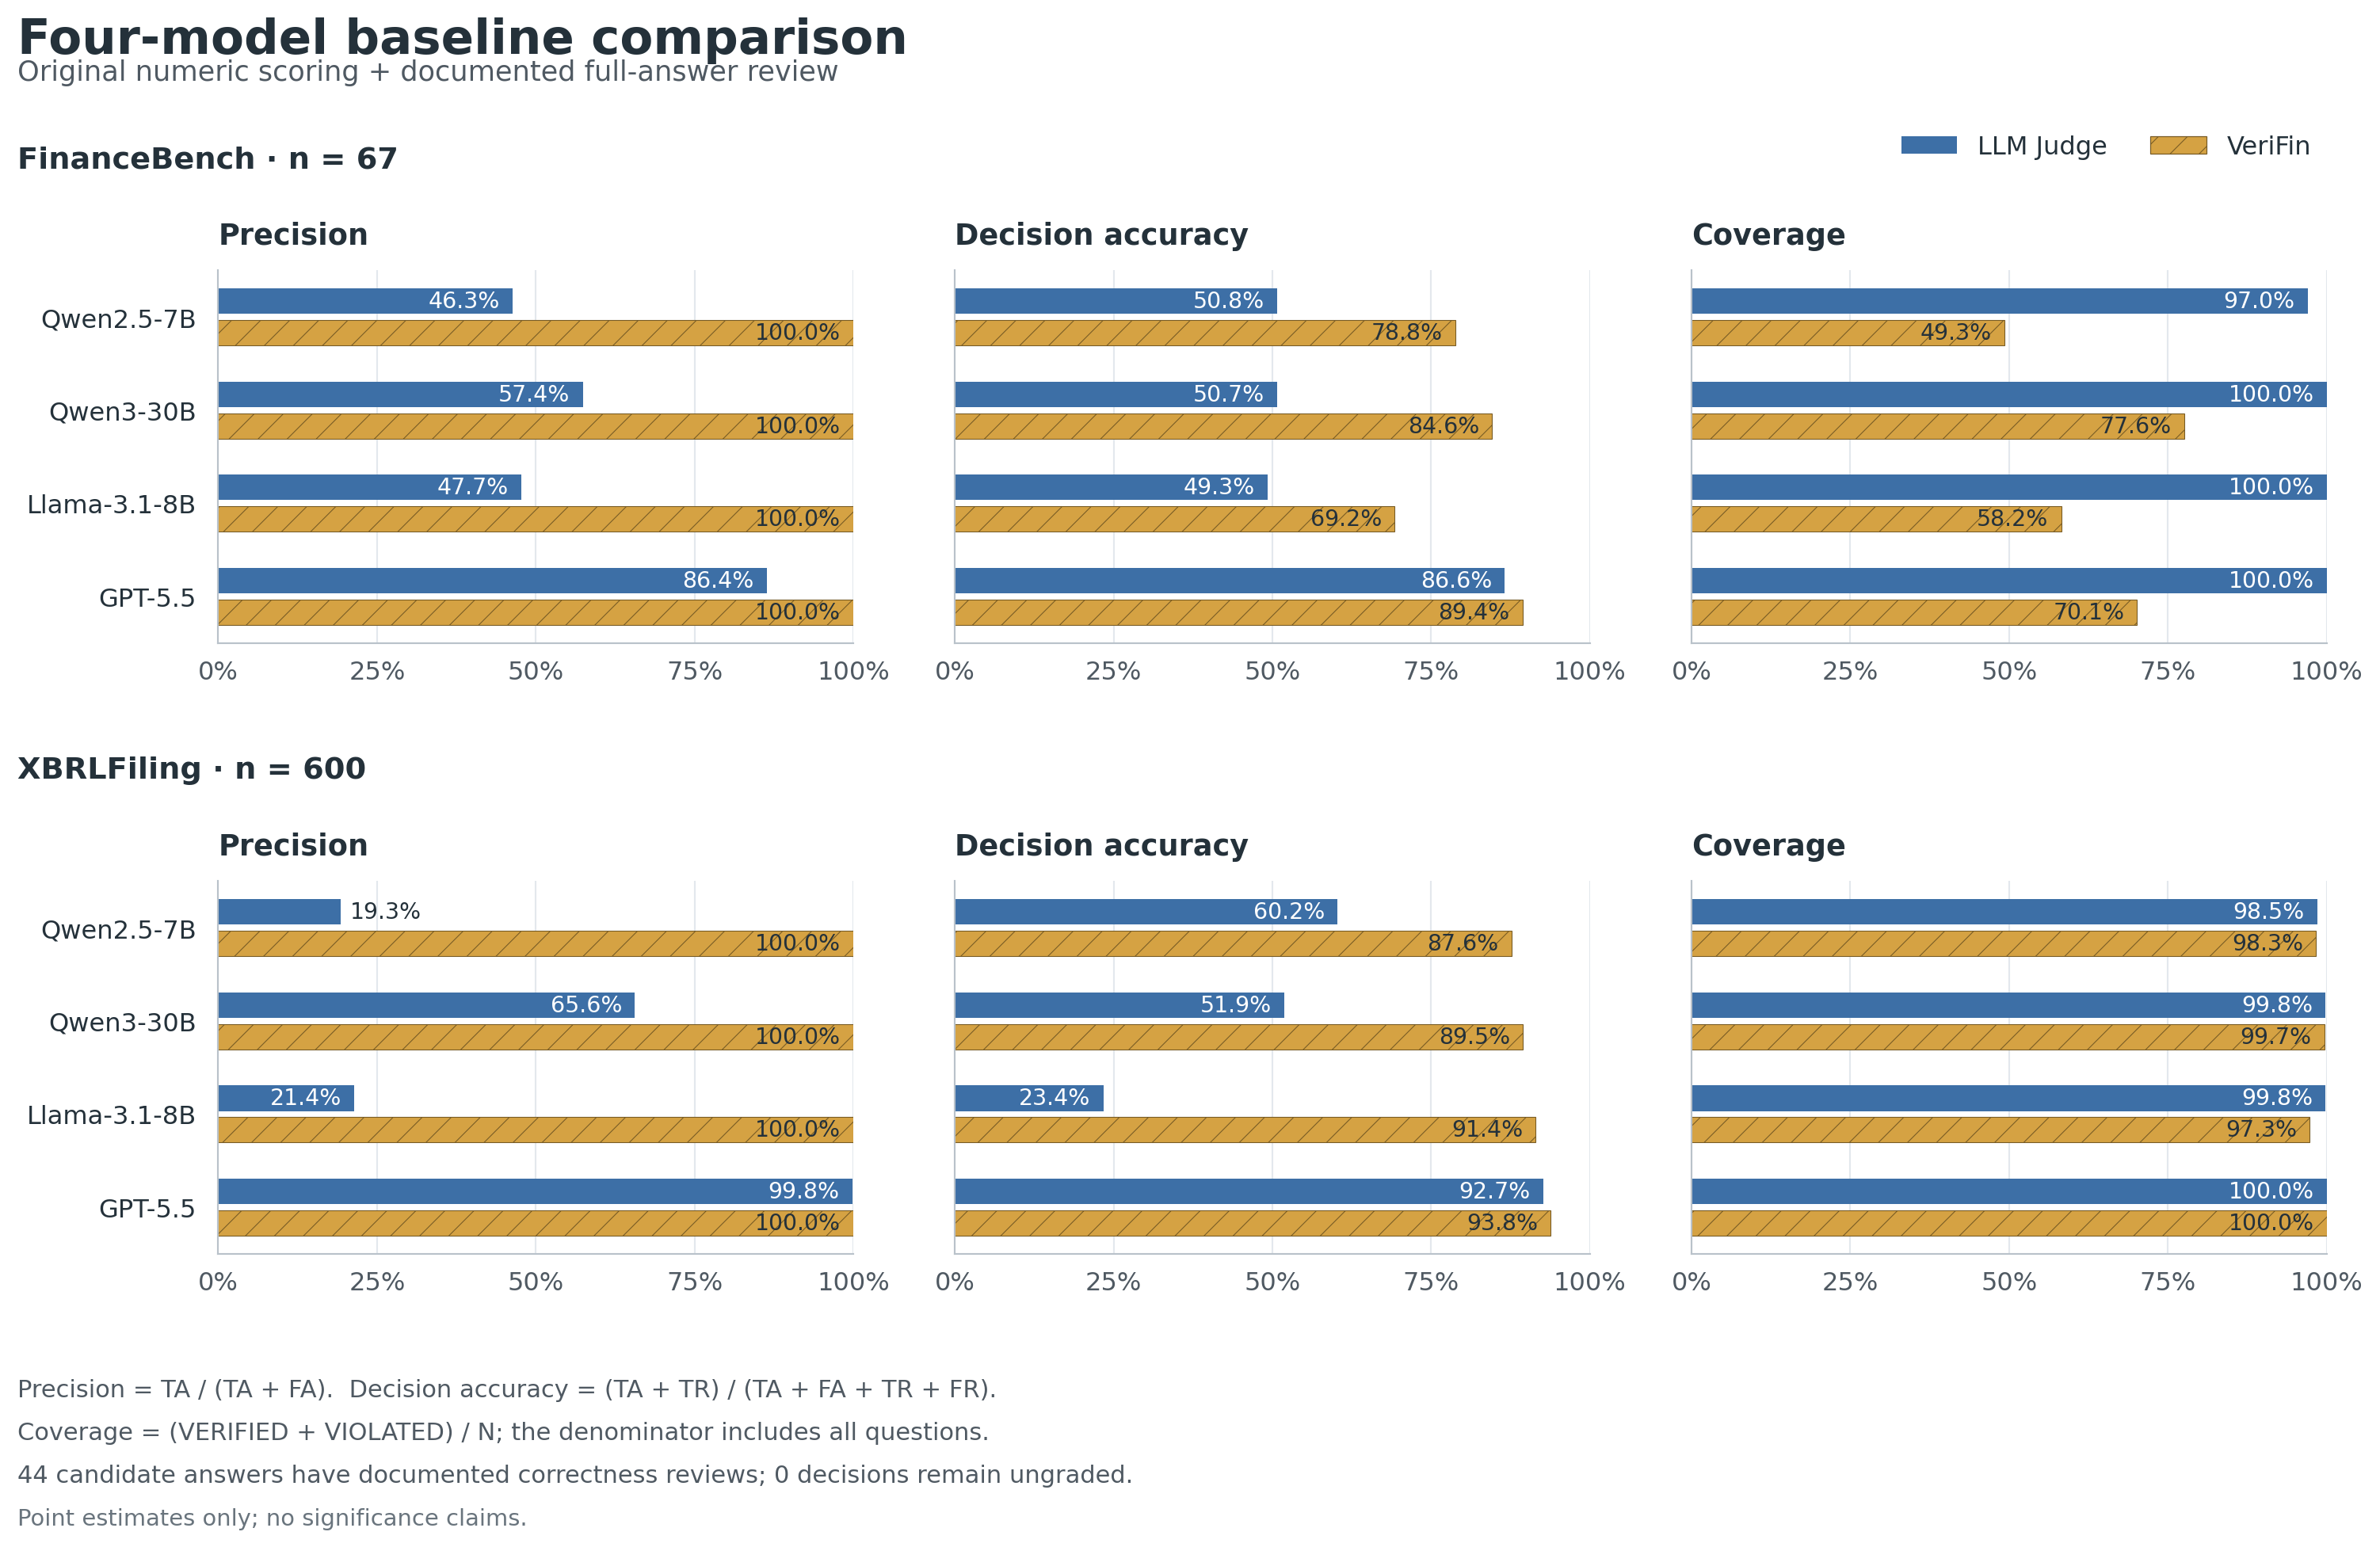

In [11]:
if not additional_comparison.empty:
    from scripts.plot_model_baselines import plot_comparison
    baseline_figure = plot_comparison(additional_comparison, additional_export_root / "figures")
    # PNG data stays inside the notebook for portable GitHub rendering.
    display(Image(filename=str(additional_export_root / "figures" /
                               "four_model_baseline_comparison.png"), width=1200))
    plt.close(baseline_figure)